In [1]:
! pip install segmentation_models
! pip install albumentations==1.3.0

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.7/50.7 kB 14.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 123.5/123.5 kB 19.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.6/49.6 MB 34.8 MB/s eta 0:00:0000:0100:01


In [1]:
import os
os.environ["SM_FRAMEWORK"] = "tf.keras"

# Model stuff
import tensorflow as tf
from tensorflow import keras
from keras.layers import Input, Conv2D
from keras.models import Model
from keras.utils import normalize
import segmentation_models as sm
from sklearn.model_selection import train_test_split

import model_utility_rpjb
import preprocess_filter
import spoketools

#path sorting
import glob
from pathlib import Path
import re

#math
import numpy as np
import matplotlib.pyplot as plt
import math
import pandas as pd

Segmentation Models: using `tf.keras` framework.


In [5]:
model_path = "models/s3_compare/"
type = "fc_aug_norm"
training_size = "105"
epoch_num = "100"
backbone = "resnet34"

model_path = f"{model_path}{type}_spoke_{training_size}im_{epoch_num}e_{backbone}.h5"
model_path

'models/s3_compare/fc_aug_norm_spoke_105im_100e_resnet34.h5'

In [6]:
X, Y = [], []

X, Y = model_utility_rpjb.data_gather(X, Y, "s3_compare", "fc_masks", aug_num = 6, filter_imgs = True)

Compose([
  ShiftScaleRotate(always_apply=False, p=1, shift_limit_x=(-0.15, 0.15), shift_limit_y=(0, 0), scale_limit=(0.0, 0.0), rotate_limit=(0, 0), interpolation=1, border_mode=4, value=None, mask_value=None, rotate_method='largest_box'),
], p=1.0, bbox_params=None, keypoint_params=None, additional_targets={})
105 105


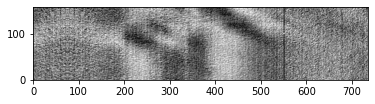

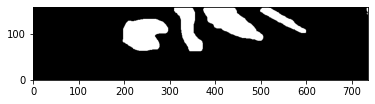

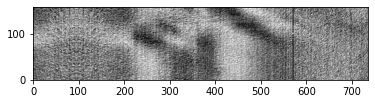

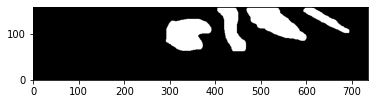

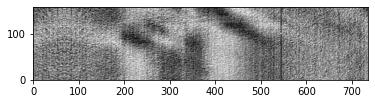

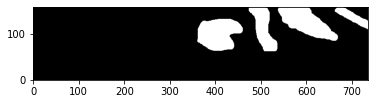

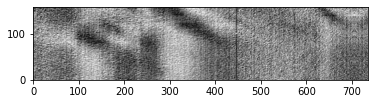

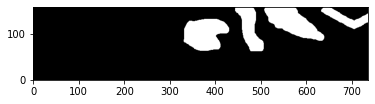

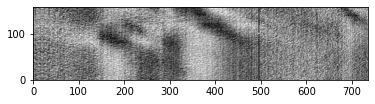

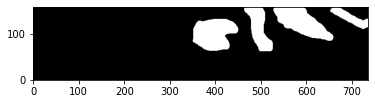

In [5]:
# file_pattern = re.compile(r'.*?(\d+).*?')
# def get_order(file):
#     match = file_pattern.match(Path(file).name)
#     if not match:
#         return math.inf
#     return int(match.groups()[0])

# sorted(glob.glob("../datasets/"+"fc_masks"+"/*.npy"), key=get_order)
for image, mask in zip(X[15:20], Y[15:20]):
    plt.imshow(image, cmap='gray', origin = 'lower')
    plt.show()
    plt.imshow(mask, cmap='gray', origin = 'lower')
    plt.show()


In [7]:
X = np.array(X)
Y = np.array(Y)
preprocess_input = sm.get_preprocessing(backbone)
X = preprocess_input(X)



# train/test split test_size = .15 for light, .25 for dark(no agu)
x_train, x_test, y_train, y_test = train_test_split(X,Y, test_size = 0.15, random_state = 42)

SIZE_Y, SIZE_X = X.shape[1], X.shape[2]
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

# for image in x_test:
#     plt.imshow(image, cmap='gray', origin = 'lower')
#     plt.show()

(89, 160, 736)
(16, 160, 736)
(89, 160, 736)
(16, 160, 736)


In [8]:
model = model_utility_rpjb.define_model(SIZE_Y, SIZE_X, backbone)

In [9]:
history = model_utility_rpjb.fit_model(x_train, y_train, model, model_path, batch_size = 10, epochs = int(epoch_num), validation_split = .13)
results = model.evaluate(x_test, y_test)
model_utility_rpjb.save_model_history(model_path, history, results)

Epoch 1/100
8/8 [==============================] - ETA: 0s - loss: 0.7606 - iou_score: 0.0786
Epoch 1: val_iou_score improved from -inf to 0.03482, saving model to models/s3_compare/fc_aug_norm_spoke_105im_100e_resnet34.h5
8/8 [==============================] - 15s 980ms/step - loss: 0.7606 - iou_score: 0.0786 - val_loss: 14.7557 - val_iou_score: 0.0348
Epoch 2/100
8/8 [==============================] - ETA: 0s - loss: 0.4291 - iou_score: 0.0893
Epoch 2: val_iou_score did not improve from 0.03482
8/8 [==============================] - 2s 200ms/step - loss: 0.4291 - iou_score: 0.0893 - val_loss: 14.7563 - val_iou_score: 0.0348
Epoch 3/100
8/8 [==============================] - ETA: 0s - loss: 0.3263 - iou_score: 0.1076
Epoch 3: val_iou_score improved from 0.03482 to 0.03504, saving model to models/s3_compare/fc_aug_norm_spoke_105im_100e_resnet34.h5
8/8 [==============================] - 2s 309ms/step - loss: 0.3263 - iou_score: 0.1076 - val_loss: 14.6590 - val_iou_score: 0.0350
Epoch 4/

In [2]:
model_path = "models/s3_compare/"
type = "fc_no_aug_norm"
training_size = "15"
epoch_num = "100"
backbone = "resnet34"

model_path = f"{model_path}{type}_spoke_{training_size}im_{epoch_num}e_{backbone}.h5"
model_path

'models/s3_compare/fc_no_aug_norm_spoke_15im_100e_resnet34.h5'

Which model is this? - fc_aug_norm_spoke_105im_1000e_resnet34.json


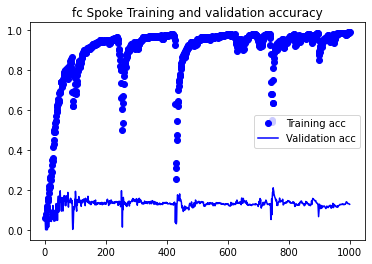

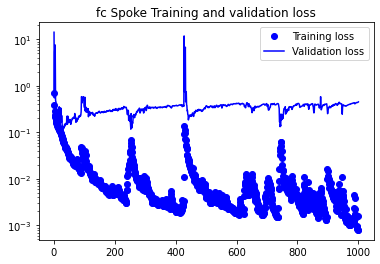

Last Train IOU Score:  0.9903448820114136
Last Train Loss Score:  0.0008188348729163408
Last Validation IOU Score:  0.12850216031074524
Last Validation Loss Score:  0.4535961151123047
fc_aug_norm
105
1000


In [9]:
model_utility_rpjb.display_results(model_path)
print(type)
print(training_size)
print(epoch_num)

fc_aug_norm
105
100
The spokes_test_rpjbs/ training set is made of 15 images
W1593706674_1_CALIB.rpjb 0


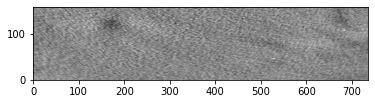

1/1 [==============================] - 1s 954ms/step


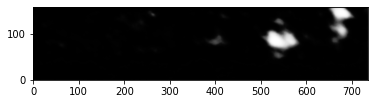

W1593706674_1_CALIB.rpjb 1


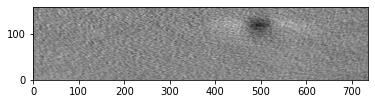

1/1 [==============================] - 0s 24ms/step


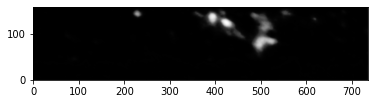

W1593706674_1_CALIB.rpjb 2


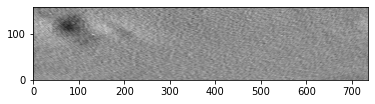

1/1 [==============================] - 0s 23ms/step


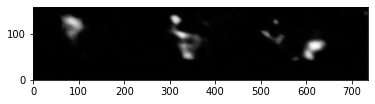

W1593706674_1_CALIB.rpjb 3


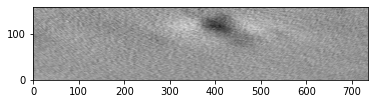

1/1 [==============================] - 0s 25ms/step


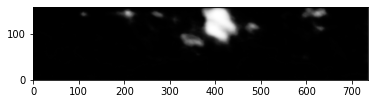

W1593706674_1_CALIB.rpjb 4


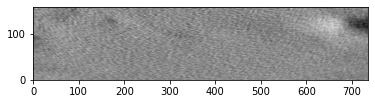

1/1 [==============================] - 0s 23ms/step


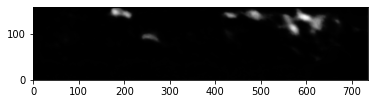

W1593706674_1_CALIB.rpjb 5


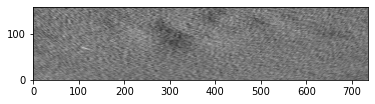

1/1 [==============================] - 0s 23ms/step


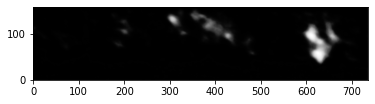

W1593706674_1_CALIB.rpjb 6


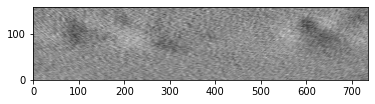

1/1 [==============================] - 0s 23ms/step


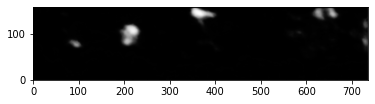

W1593706674_1_CALIB.rpjb 7


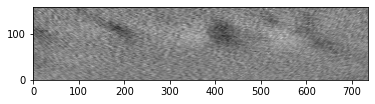

1/1 [==============================] - 0s 25ms/step


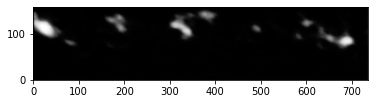

W1593706674_1_CALIB.rpjb 8


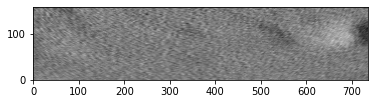

1/1 [==============================] - 0s 24ms/step


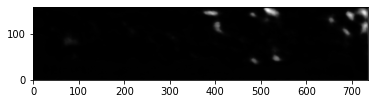

W1593706674_1_CALIB.rpjb 9


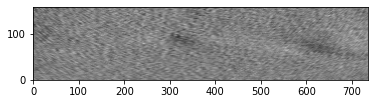

1/1 [==============================] - 0s 23ms/step


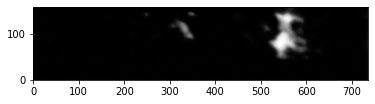

W1593706674_1_CALIB.rpjb 10


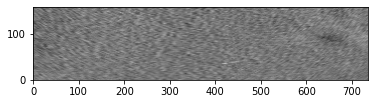

1/1 [==============================] - 0s 24ms/step


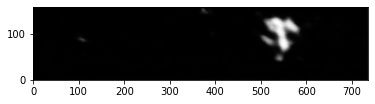

W1593706674_1_CALIB.rpjb 11


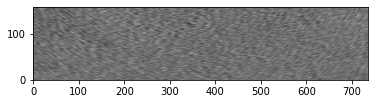

1/1 [==============================] - 0s 24ms/step


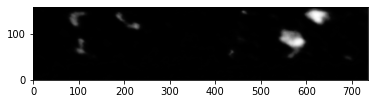

W1593706674_1_CALIB.rpjb 12


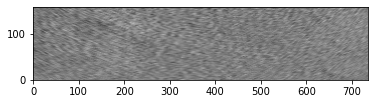

1/1 [==============================] - 0s 23ms/step


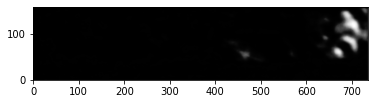

W1593706674_1_CALIB.rpjb 13


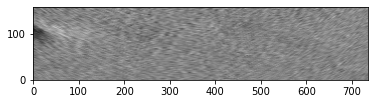

1/1 [==============================] - 0s 22ms/step


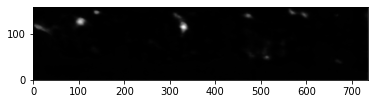

W1593706674_1_CALIB.rpjb 14


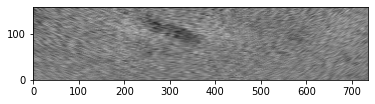

1/1 [==============================] - 0s 22ms/step


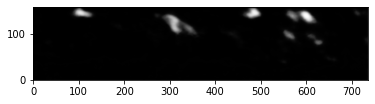

In [10]:
model = keras.models.load_model(model_path, compile = False)
model.compile(optimizer = "Adam" , loss = "binary_crossentropy", metrics = [sm.metrics.IOUScore()], )
print(type)
print(training_size)
print(epoch_num)

model_utility_rpjb.model_testing(model, "spokes_test_rpjbs", 15, filter_imgs = True)